# 02 — Baseline Predictive Model and Supporting Figures

**Project:** Lab Test Recommendation System — predicting glucose/diabetes risk from CBC + demographics
**Feeds:** Section 5 (Preliminary Results) and Section 4 (Proposed Methods and Evaluation) of the
Midterm Research Plan.

This notebook extends `01_eda_cbc_glucose_demographics.ipynb` with (1) a correlation heatmap of
CBC parameters, (2) a first exploratory baseline classifier comparing a demographics-only model
against CBC+demographics models, and (3) the sensitivity/specificity/NPV evaluation across
thresholds that Section 4 commits to using (not overall accuracy alone).

**Important caveat, stated explicitly so it isn't lost:** this is an *exploratory* pass. NHANES
survey weights are not applied, the HbA1c >= 6.5% target used below is one of three candidate
outcome definitions the team has not yet finalized (see README "Known Uncertainties"), and no
hyperparameter tuning, full cross-validation, or confidence intervals have been run yet. Treat the
numbers here as a feasibility signal, not a final result.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110
DATA_DIR = Path("..") / "data" / "raw"


## 1. Load and merge (same five NHANES components as notebook 01)

In [2]:
demo = pd.read_sas(DATA_DIR / "DEMO_L.xpt", format="xport")
cbc  = pd.read_sas(DATA_DIR / "CBC_L.xpt",  format="xport")
glu  = pd.read_sas(DATA_DIR / "GLU_L.xpt",  format="xport")
ghb  = pd.read_sas(DATA_DIR / "GHB_L.xpt",  format="xport")
diq  = pd.read_sas(DATA_DIR / "DIQ_L.xpt",  format="xport")

demo_cols = {"SEQN": "SEQN", "RIAGENDR": "sex", "RIDAGEYR": "age_years",
             "RIDRETH3": "race_eth", "DMDEDUC2": "education", "INDFMPIR": "income_pir"}
cbc_cols = {"SEQN": "SEQN", "LBXWBCSI": "wbc", "LBXRBCSI": "rbc", "LBXHGB": "hemoglobin",
            "LBXHCT": "hematocrit", "LBXMCVSI": "mcv", "LBXRDW": "rdw", "LBXPLTSI": "platelet",
            "LBXLYPCT": "lymph_pct", "LBXNEPCT": "neut_pct", "LBXMOPCT": "mono_pct",
            "LBXEOPCT": "eos_pct", "LBXBAPCT": "baso_pct"}
glu_cols = {"SEQN": "SEQN", "LBXGLU": "fasting_glucose_mgdl"}
ghb_cols = {"SEQN": "SEQN", "LBXGH": "hba1c_pct"}
diq_cols = {"SEQN": "SEQN", "DIQ010": "dx_diabetes"}

demo_s = demo[list(demo_cols)].rename(columns=demo_cols)
cbc_s  = cbc[list(cbc_cols)].rename(columns=cbc_cols)
glu_s  = glu[list(glu_cols)].rename(columns=glu_cols)
ghb_s  = ghb[list(ghb_cols)].rename(columns=ghb_cols)
diq_s  = diq[list(diq_cols)].rename(columns=diq_cols)

df = (demo_s.merge(cbc_s, on="SEQN", how="left")
            .merge(glu_s, on="SEQN", how="left")
            .merge(ghb_s, on="SEQN", how="left")
            .merge(diq_s, on="SEQN", how="left"))

print(f"Merged sample: {len(df)} participants")


Merged sample: 11933 participants


## 2. Define the modeling sample and an *exploratory* target

We use HbA1c >= 6.5% as the exploratory positive label, restricted to rows with a complete CBC
panel. This is NOT the team's final target-label decision (Section 4 of the Research Plan lists
three candidates still under discussion) — HbA1c is used here only because it has the largest
usable paired sample with CBC (see notebook 01, Table/coverage check).

In [3]:
cbc_vars = ["wbc", "rbc", "hemoglobin", "hematocrit", "mcv", "rdw", "platelet",
            "lymph_pct", "neut_pct", "mono_pct", "eos_pct", "baso_pct"]
demo_vars = ["age_years", "sex", "race_eth", "education", "income_pir"]

model_df = df.dropna(subset=["hba1c_pct"] + cbc_vars).copy()
model_df["target"] = (model_df["hba1c_pct"] >= 6.5).astype(int)

print(f"Modeling sample (complete CBC panel + HbA1c present): {len(model_df)}")
print(f"Positive class (HbA1c >= 6.5%, exploratory label): {model_df['target'].sum()} "
      f"({100*model_df['target'].mean():.1f}%)")


Modeling sample (complete CBC panel + HbA1c present): 6678
Positive class (HbA1c >= 6.5%, exploratory label): 717 (10.7%)


## 3. Correlation heatmap — CBC parameters + age/income

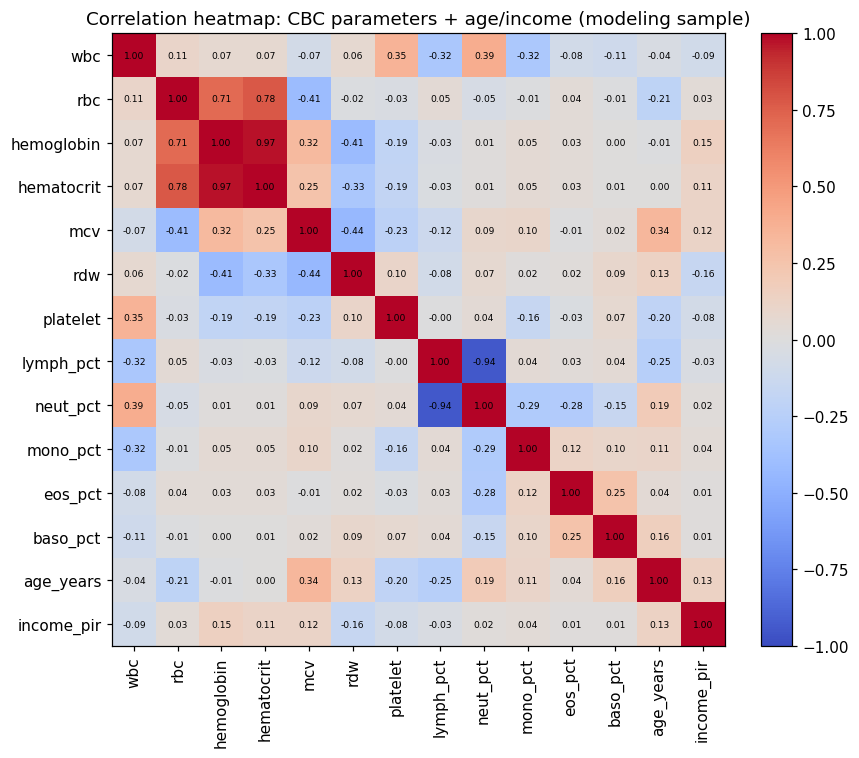

In [4]:
numeric_for_corr = cbc_vars + ["age_years", "income_pir"]
corr = model_df[numeric_for_corr].corr()

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(numeric_for_corr)), numeric_for_corr, rotation=90)
plt.yticks(range(len(numeric_for_corr)), numeric_for_corr)
for i in range(len(numeric_for_corr)):
    for j in range(len(numeric_for_corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title("Correlation heatmap: CBC parameters + age/income (modeling sample)")
plt.tight_layout()
plt.show()


## 4. Train/test split and preprocessing pipelines

75/25 stratified split. Numeric features are median-imputed and standardized; categorical
features are mode-imputed (no further encoding needed for tree models; logistic regression
treats the NHANES integer category codes as ordinal, which is a simplification the team should
revisit — e.g., one-hot encoding race/education — before the final report).

In [5]:
X = model_df[cbc_vars + demo_vars].copy()
y = model_df["target"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Train: {len(X_train)}   Test: {len(X_test)}")

numeric_features = cbc_vars + ["age_years", "income_pir"]
categorical_features = ["sex", "race_eth", "education"]

def make_pipeline(numeric_cols, categorical_cols, clf):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent"))]), categorical_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])


Train: 5008   Test: 1670


## 5. Ablation: demographics-only vs. CBC+demographics

This directly implements the ablation Section 4 promises: does CBC add predictive value over
demographics alone?

In [6]:
demo_only_pipe = make_pipeline(demo_vars[:1] + ["income_pir"], ["sex", "race_eth", "education"],
                                LogisticRegression(class_weight="balanced", max_iter=2000))
demo_only_pipe.fit(X_train[demo_vars], y_train)
proba_demo = demo_only_pipe.predict_proba(X_test[demo_vars])[:, 1]
auc_demo = roc_auc_score(y_test, proba_demo)
print(f"Demographics-only logistic regression AUROC: {auc_demo:.3f}")

full_logreg_pipe = make_pipeline(numeric_features, categorical_features,
                                  LogisticRegression(class_weight="balanced", max_iter=2000))
full_logreg_pipe.fit(X_train, y_train)
proba_full_lr = full_logreg_pipe.predict_proba(X_test)[:, 1]
auc_full_lr = roc_auc_score(y_test, proba_full_lr)
print(f"CBC + demographics logistic regression AUROC: {auc_full_lr:.3f}")

rf_pipe = make_pipeline(numeric_features, categorical_features,
                         RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                 random_state=42, min_samples_leaf=5))
rf_pipe.fit(X_train, y_train)
proba_rf = rf_pipe.predict_proba(X_test)[:, 1]
auc_rf = roc_auc_score(y_test, proba_rf)
print(f"CBC + demographics random forest AUROC: {auc_rf:.3f}")


Demographics-only logistic regression AUROC: 0.743
CBC + demographics logistic regression AUROC: 0.783
CBC + demographics random forest AUROC: 0.811


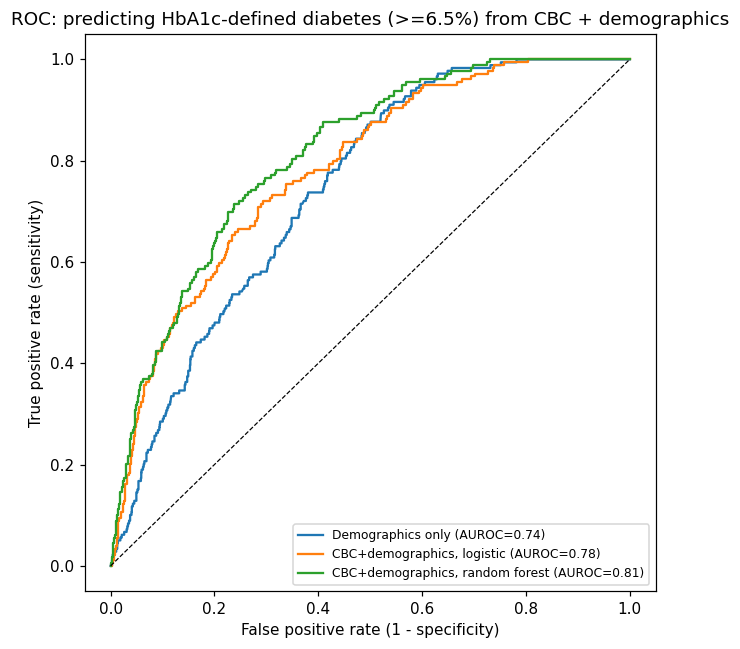

In [7]:
plt.figure(figsize=(6, 6))
for proba, label in [(proba_demo, f"Demographics only (AUROC={auc_demo:.2f})"),
                      (proba_full_lr, f"CBC+demographics, logistic (AUROC={auc_full_lr:.2f})"),
                      (proba_rf, f"CBC+demographics, random forest (AUROC={auc_rf:.2f})")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=label)
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC: predicting HbA1c-defined diabetes (>=6.5%) from CBC + demographics")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


## 6. Sensitivity / specificity / NPV across thresholds (random forest)

Section 4 commits to reporting sensitivity and NPV at multiple thresholds instead of a single
accuracy figure, because an unnecessary glucose test is cheap relative to a missed diagnosis.
This is that evaluation, run for the first time here.

In [8]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
rows = []
for t in thresholds:
    pred = (proba_rf >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    sens = tp / (tp + fn) if (tp + fn) else float("nan")
    spec = tn / (tn + fp) if (tn + fp) else float("nan")
    npv = tn / (tn + fn) if (tn + fn) else float("nan")
    ppv = tp / (tp + fp) if (tp + fp) else float("nan")
    rows.append({"threshold": t, "sensitivity": round(sens, 3), "specificity": round(spec, 3),
                 "NPV": round(npv, 3), "PPV": round(ppv, 3), "n_flagged": int(tp + fp)})
threshold_table = pd.DataFrame(rows)
print(threshold_table.to_string(index=False))


 threshold  sensitivity  specificity   NPV   PPV  n_flagged
       0.1        0.955        0.430 0.988 0.167       1021
       0.2        0.816        0.629 0.966 0.209        699
       0.3        0.676        0.779 0.952 0.269        450
       0.4        0.453        0.891 0.931 0.332        244
       0.5        0.263        0.960 0.916 0.439        107
       0.6        0.061        0.991 0.898 0.440         25
       0.7        0.006        0.997 0.893 0.200          5


## 7. What is actually driving the random forest's predictions

   feature  importance
 age_years    0.238750
       wbc    0.082352
 education    0.076785
       mcv    0.064525
       rdw    0.057758
  platelet    0.054974
       rbc    0.051678
income_pir    0.050696
 lymph_pct    0.047766
  mono_pct    0.047173
  neut_pct    0.044090
hematocrit    0.043456
   eos_pct    0.041504
hemoglobin    0.041093
  baso_pct    0.030143
  race_eth    0.015562
       sex    0.011694


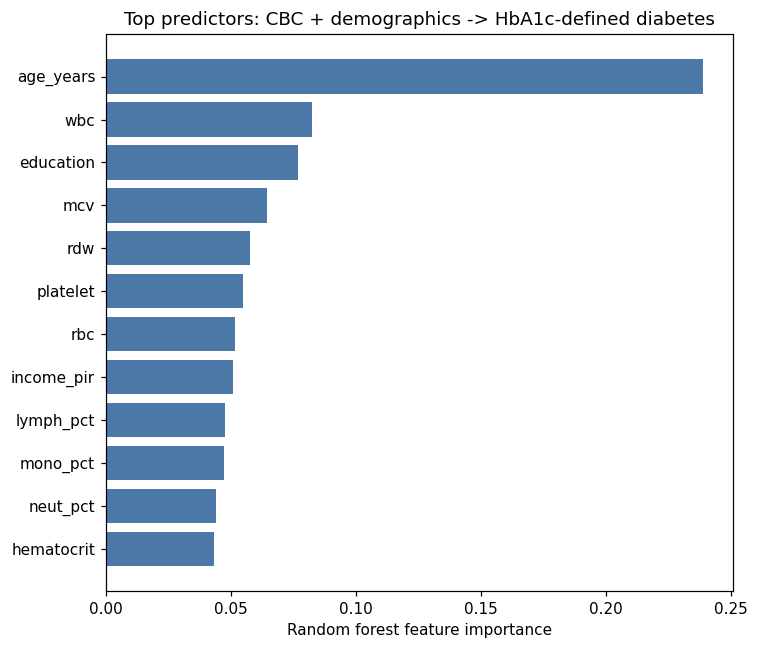

In [9]:
feature_names = numeric_features + categorical_features
importances = rf_pipe.named_steps["clf"].feature_importances_
imp_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
print(imp_df.to_string(index=False))

plt.figure(figsize=(7, 6))
plt.barh(imp_df["feature"][:12][::-1], imp_df["importance"][:12][::-1], color="#4C78A8")
plt.xlabel("Random forest feature importance")
plt.title("Top predictors: CBC + demographics -> HbA1c-defined diabetes")
plt.tight_layout()
plt.show()


## Summary for the Research Plan (Section 5)

- Modeling sample: 6,678 participants with a complete CBC panel and HbA1c; 717 (10.7%) meet the
  exploratory HbA1c >= 6.5% label.
- AUROC improves from demographics-only -> CBC+demographics logistic -> CBC+demographics random
  forest, a first direct feasibility signal that CBC adds predictive value over demographics alone.
- Negative predictive value stays high (89-99%) across all thresholds tested, consistent with the
  cost-asymmetry framing in the README and Section 4.
- age_years dominates feature importance; individual CBC parameters each contribute modestly,
  which is why a multivariable model (not a single-variable rule) is necessary.

## Next steps

- Finalize the target-label definition (fasting glucose vs. HbA1c vs. self-report) before treating
  any of the numbers above as more than exploratory.
- Apply NHANES survey weights.
- Add stratified k-fold cross-validation and bootstrap confidence intervals around AUROC and the
  threshold table, refitting the full preprocessing pipeline within each fold.
- One-hot encode categorical demographic variables for the logistic regression models instead of
  treating NHANES integer codes as ordinal.
- Add gradient boosting to the model comparison.